# How much of the early LARRY fate signal comes from later culture cells?

## Biological idea and study design

The [LARRY study](https://doi.org/10.1126/science.aaw3381) follows hematopoietic cells through differentiation while retaining clonal barcodes. Here the practical question is whether early and later undifferentiated compartments differ in their inferred association with monocytic and neutrophil outcomes when the transition graph is estimated from **genuine spliced/unspliced molecules**.

We use the [Pyro-Velocity count deposit](https://doi.org/10.6084/m9.figshare.20780344.v1), whose authors report dropEst/velocyto processing of the original inDrop data. The public file is H5AD; we export its actual raw splicing layers to a verified loom and read them back. This is a lossless storage-format conversion, not reconstruction of velocity counts from gene expression.

We restrict the comparison to the same starting population, Lin−Kit+Sca1+, at day 2 and day 4. A documented cap per source-state/time stratum keeps this teaching workflow practical; full eligible composition is reported before sampling. **Culture time is not a treatment contrast.** The workflow does not interpret sequencing libraries, culture labels or clone barcodes as independent treatment replicates. Clone information is not used to build the velocity model or the supervised score, and this notebook does not claim held-out clonal predictive validation.

## Environment and reproducible settings

In [1]:
from pathlib import Path
import sys

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

In [2]:
from pathlib import Path
import sys
import importlib.metadata as metadata
import platform
import json

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc
import scvelo as scv
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
import scCS
from benchmarks.validation.velocity_inputs import audit_counts, write_verified_loom

# Keep figures embedded in Jupyter and the exported documentation.
matplotlib.use("module://matplotlib_inline.backend_inline", force=True)

SEED = 19
np.random.seed(SEED)
DATA = PROJECT / "data" / "validation"
OUTPUT_DIR = PROJECT / "tutorial_outputs" / "larry_pair_velocity"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for package in ["scCS-py", "scanpy", "scvelo", "anndata"]:
    print(package, metadata.version(package))
plt.rcParams.update({"figure.dpi": 90, "figure.figsize": (7, 4)})

scCS-py 1.0.1.dev0
scanpy 1.12.6
scvelo 0.3.4
anndata 0.13.4


## 1. Load and audit genuine splicing counts

The original 1.53 GB count object is downloaded once and checked against the source MD5. The loader reads only the selected sparse layers; the expression-only CoSpar object and its chronological neighbor graph are not inputs to this analysis. The selected gene screen retains prespecified markers. Set `max_per_stratum=None` to retain all eligible cells, recognizing that this changes the graph and requires a new fit. Counts after stratified sampling must not be interpreted as biological abundance.

In [3]:
from benchmarks.validation.velocity_inputs import load_larry_counts

raw, composition, manifest = load_larry_counts(DATA, max_per_stratum=600, n_genes=2000, seed=SEED)
print(json.dumps(manifest, indent=2))
display(composition)
composition.to_csv(OUTPUT_DIR / "full_eligible_composition.csv")
display(audit_counts(raw))
raw.obs["clusters"] = raw.obs.source_state.map(
    {"Undifferentiated": "Root", "Monocyte": "Monocytic", "Neutrophil": "Neutrophil"}
).fillna("Outside")
display(pd.crosstab(raw.obs.source_state, raw.obs.condition))
(OUTPUT_DIR / "count_provenance.json").write_text(json.dumps(manifest, indent=2))

{
  "source": "https://ndownloader.figshare.com/files/37028569",
  "source_md5": "d618305c0ee0e41570b1147e63df332a",
  "starting_population": "Lin-Kit+Sca1+",
  "days": [
    2,
    4
  ],
  "max_per_state_time": 600,
  "requested_genes": 2000,
  "seed": 19,
  "eligible_cells": 8930,
  "loaded_cells": 2083,
  "clone_information_used_for_model": false
}


time_info,2.0,4.0
state_info,,
Baso,9,172
Ccr7_DC,7,2
Eos,0,4
Erythroid,3,0
Lymphoid,14,86
Mast,2,55
Meg,1,18
Monocyte,1,386
Neutrophil,2,120


,layer,cells,genes,total_counts,nonzero_entries
0,spliced,2083,2002,1433402.0,906941
1,unspliced,2083,2002,154804.0,138527


condition,day2,day4
source_state,,
Baso,9,172
Ccr7_DC,7,2
Eos,0,4
Erythroid,3,0
Lymphoid,14,86
Mast,2,55
Meg,1,18
Monocyte,1,386
Neutrophil,2,120


**What was actually observed on day 2?** Before sampling there are 2,770 undifferentiated LSK cells, one annotated monocyte and two annotated neutrophils. Day 4 contains 5,277 undifferentiated cells, 386 monocytes and 120 neutrophils. The cap selects 600 roots per day. Apparent equality of root counts in the fitted object comes from sampling.

## 2. Read the analysis loom and verify exact count identity

For a uniform loom-based workflow we export the selected **measured** counts, then verify that cell IDs, gene IDs and both layers survive the round trip exactly. The output loom is an analysis subset, not a new raw-read quantification. Existing mismatched count files raise an error rather than silently substituting different input. The generated file is local data and is not bundled into the package.

In [4]:
LOOM_PATH = DATA / "larry_LSK_day2_day4_cap600_g2000_seed19.loom"
write_verified_loom(raw, LOOM_PATH)
adata = ad.read_loom(LOOM_PATH, obs_names="CellID", var_names="Gene", sparse=True)
display(audit_counts(adata))
print("Verified analysis loom:", LOOM_PATH)
del raw

Verified analysis loom: /workspace/scratch/1a48413c8396/replay/data/validation/larry_LSK_day2_day4_cap600_g2000_seed19.loom


,layer,cells,genes,total_counts,nonzero_entries
0,spliced,2083,2002,1433402.0,906941
1,unspliced,2083,2002,154804.0,138527


## 3. Fit RNA velocity in expression space

The velocity estimator sees the measured spliced/unspliced layers and the native expression-neighbor graph. It never sees the scCS star coordinates. This tutorial runs the same dynamical scVelo workflow as the pancreas and Schwann PairScorer examples: `recover_dynamics(max_iter=20)`, dynamical velocity, velocity graph, inferred terminal states and latent time. Twenty iterations are a tutorial setting, not a convergence guarantee or a claim to reproduce a published Bayesian model. The model choice, count filtering, neighborhood and gene screen are assumptions to inspect before interpreting fate scores. A matching UMAP is recomputed for visualization only.

Filtered out 298 genes that are detected 10 counts (shared).
Normalized count data: X, spliced, unspliced.
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
recovering dynamics (using 1/9 cores)
    finished (0:01:42) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/9 cores)
    finished (0:00:01) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
--> added 'velocity_length' (adata.obs)
--> added 'velocity_confidence' (adata.obs)
--> added 'velocity_confidence_transition' (adata.obs)
computing terminal states
    identified 1 region of root cells and 1 region of end points .
    finished (0:00:00) --> added
    'root_cells', root cells of Markov diffusion process (adata.obs

velocity_length           velocity_confidence          
                   median      mean              median      mean
condition                                                        
day2                2.890  2.899014            0.765580  0.755837
day4                2.955  3.005194            0.797169  0.781752

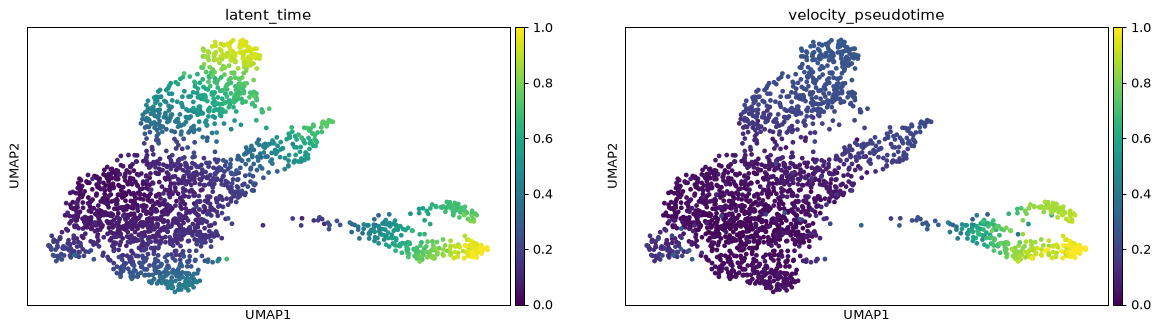

In [5]:
# Processing uses measured spliced/unspliced molecules, before any scCS display.
scv.pp.filter_genes(adata, min_shared_counts=10)
scv.pp.normalize_per_cell(adata)
sc.pp.log1p(adata)
sc.pp.pca(adata, n_comps=30, random_state=SEED)
sc.pp.neighbors(adata, n_neighbors=30, n_pcs=30, random_state=SEED)
sc.tl.umap(adata, random_state=SEED)
scv.pp.moments(adata, n_neighbors=None, n_pcs=None)
scv.tl.recover_dynamics(adata, max_iter=20, n_jobs=1, show_progress_bar=False)
scv.tl.velocity(adata, mode="dynamical")
scv.tl.velocity_graph(adata, n_jobs=1, show_progress_bar=False)
scv.tl.velocity_confidence(adata)
scv.tl.terminal_states(adata)
adata.obs["early_root_hint"] = (
    adata.obs.clusters.eq("Root")
    & adata.obs.condition.eq("day0" if "day0" in set(adata.obs.condition) else "day2")
).astype(float)
scv.tl.latent_time(adata, root_key="early_root_hint", end_key="end_points")
scv.tl.velocity_pseudotime(adata, root_key="early_root_hint")
print("Dynamically fitted genes:", int(adata.var.fit_likelihood.notna().sum()))
transition = scCS.get_scvelo_transition_matrix(adata)
adata.obsp["T_velocity"] = transition
print("Fitted velocity genes:", int(adata.var.velocity_genes.sum()))
display(
    adata.obs.groupby("condition", observed=True)[["velocity_length", "velocity_confidence"]].agg(
        ["median", "mean"]
    )
)
assert transition.shape == (adata.n_obs, adata.n_obs)
assert np.isfinite(transition.data).all()
sc.pl.umap(adata, color=["latent_time", "velocity_pseudotime"], show=False)
plt.show()

## 4. Inspect the native field and phase portraits

Arrows are estimated from the fitted RNA-velocity model. Smoothness in a stream plot and agreement among neighbors are diagnostics, not independent evidence of correct cell fate. The phase portraits use the two highest-likelihood dynamically fitted velocity genes; they are selected for fit inspection, not because their arrows support a proposed direction of differentiation. The displayed source annotations and sampled conditions let you assess overlap and gross inconsistencies.

computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)
Phase portraits selected by dynamical fit likelihood: [np.str_('Ctsc'), np.str_('Dab2')]


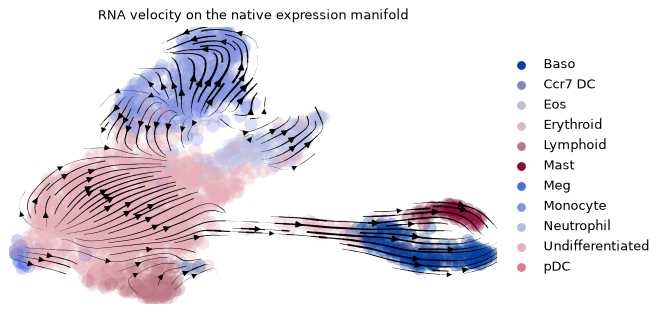

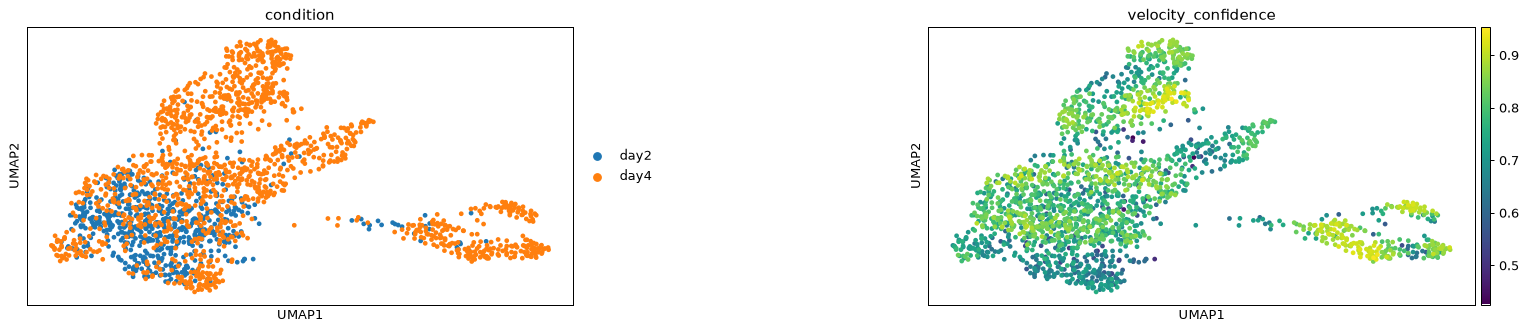

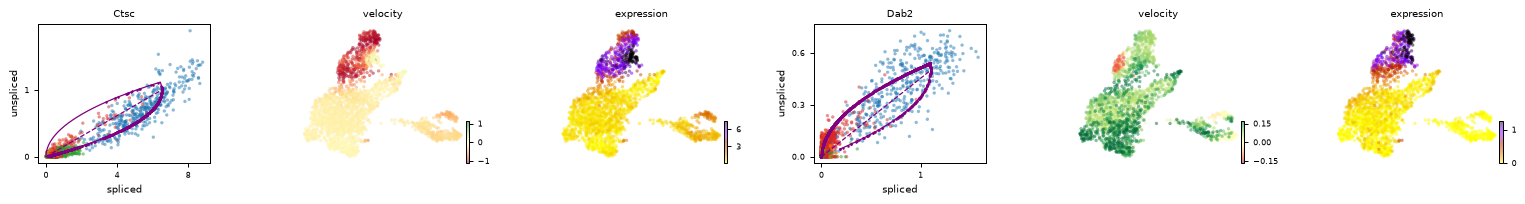

In [6]:
scv.pl.velocity_embedding_stream(
    adata,
    basis="umap",
    color="source_state",
    legend_loc="right margin",
    title="RNA velocity on the native expression manifold",
    show=False,
)
plt.show()
sc.pl.umap(adata, color=["condition", "velocity_confidence"], wspace=0.5, show=False)
plt.show()
phase_genes = (
    adata.var.loc[adata.var.velocity_genes]
    .sort_values("fit_likelihood", ascending=False)
    .head(2)
    .index.tolist()
)
print("Phase portraits selected by dynamical fit likelihood:", phase_genes)
if phase_genes:
    scv.pl.velocity(adata, var_names=phase_genes, ncols=2, show=False)
    plt.show()

## 5. Define the supervised question and velocity pseudotime

Undifferentiated cells form the root; monocytes and neutrophils are the selected outcomes. Other annotated states remain in the native graph as unselected context. Velocity pseudotime is rooted in the early undifferentiated population and supplies a continuous ordering. Because it is computed from the same velocity graph, it is not independent chronological evidence. Actual day labels are retained separately and never used to force forward transition edges.

Using velocity pseudotime computed during the dynamical workflow.


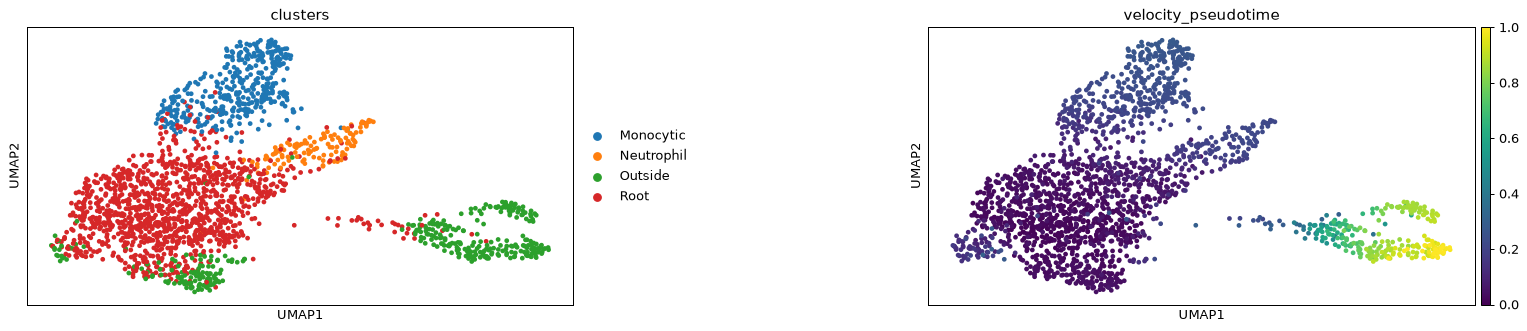

In [7]:
ROOT_LABEL = "Root"
FATES = ["Monocytic", "Neutrophil"]
REPLICATE_KEY = None
MARKER_GENES = ["Kit", "Lyz2", "Mpo", "Gata2"]
adata.obs["clusters"] = pd.Categorical(adata.obs.clusters)
adata.obs["early_root_hint"] = (
    adata.obs.clusters.eq("Root") & adata.obs.condition.eq("day2")
).astype(float)
print("Using velocity pseudotime computed during the dynamical workflow.")
ORDERING_KEY = "velocity_pseudotime"
if not np.isfinite(adata.obs[ORDERING_KEY]).all():
    raise ValueError("Velocity pseudotime is undefined for some cells; inspect graph connectivity.")
sc.pl.umap(adata, color=["clusters", ORDERING_KEY], wspace=0.5, show=False)
plt.show()

## 6. Preflight, shared geometry and PairScorer

The pooled fit uses one graph, ordering and anchor definition for both conditions. Background states remain in the native graph even though the supervised display contains the selected root and fates. `min_replicates=1` permits descriptive score summaries only; it does not authorize formal inference for the day-2 and day-4 samples from the same starting population. The preflight replication errors are retained as such, while structural errors stop execution. Inspect the post-fit report for dead ends, unreachable outcomes and defined-affinity coverage.

In [8]:
pair = scCS.PairScorer(
    adata,
    root=ROOT_LABEL,
    branches=FATES,
    obs_key="clusters",
    condition_obs_key="condition",
    replicate_obs_key=REPLICATE_KEY,
    condition_order=["day0", "day2"] if REPLICATE_KEY == "patient" else ["day2", "day4"],
)
report = pair.preflight(ordering_metric=ORDERING_KEY, check_velocity=True)
report.display()
expected_design_errors = {f"condition_{condition}_replicates" for condition in pair.conditions}
unexpected = [d for d in report.errors if d.code not in expected_design_errors]
if unexpected:
    raise ValueError("Structural preflight failure: " + "; ".join(d.message for d in unexpected))
if report.errors:
    print("Replication errors remain: descriptive scoring only; formal inference is unavailable.")
pair.build_embedding(ordering_metric=ORDERING_KEY, cache_subset=False, verbose=False)
FUTURE_OPTIONS = {"effective_horizon": 64, "anchor_quantile": 0.9, "min_anchor_cells": 3}
pair.fit(
    transition_matrix=transition,
    scoring_mode="future_fate",
    transition_scope="pooled",
    future_fate_options=FUTURE_OPTIONS,
    verbose=False,
)
results = pair.score_all_conditions(
    population="root", min_cells=5, min_replicates=1, write_to_adata=False, verbose=False
)
postflight = pair.preflight(ordering_metric=ORDERING_KEY, check_velocity=True)
postflight.display()
unexpected = [d for d in postflight.errors if d.code not in expected_design_errors]
if unexpected:
    raise ValueError("Post-fit structural failure: " + "; ".join(d.message for d in unexpected))
postflight.to_frame().to_csv(OUTPUT_DIR / "preflight.csv", index=False)

,level,code,message,value
0,info,furcation_valid,Root and terminal annotations are valid.,1709.0
1,info,root_cells,Root population contains 1200 cells.,1200.0
2,info,terminal_Monocytic,Terminal 'Monocytic' contains 387 cells.,387.0
3,info,terminal_Neutrophil,Terminal 'Neutrophil' contains 122 cells.,122.0
4,info,ordering_valid,Ordering metric is finite and non-constant amo...,1.0
5,info,ordering_resolution,Root ordering has 1200 unique values across 12...,1.0
6,info,velocity_available,Velocity information is available.,NaN
7,info,condition_day2_cells,Condition 'day2' contains 639 cells.,639.0
8,info,condition_day4_cells,Condition 'day4' contains 1444 cells.,1444.0
9,warning,replicate_key_missing,No replicate key was supplied; formal conditio...,NaN


,level,code,message,value
0,info,furcation_valid,Root and terminal annotations are valid.,1709.000000
1,info,root_cells,Root population contains 1200 cells.,1200.000000
2,info,terminal_Monocytic,Terminal 'Monocytic' contains 387 cells.,387.000000
3,info,terminal_Neutrophil,Terminal 'Neutrophil' contains 122 cells.,122.000000
4,info,ordering_valid,Ordering metric is finite and non-constant amo...,1.000000
5,info,ordering_resolution,Root ordering has 1200 unique values across 12...,1.000000
6,info,velocity_available,Velocity information is available.,NaN
7,info,graph_dead_end_nonanchors,0 selected non-anchor cells have no positive o...,0.000000
8,info,root_unreachable_selected_anchors,0 root cells have no graph path to selected an...,0.000000
9,info,transition_coverage,"Root transition coverage median=1.000, q05=0.830.",0.830069


## 7. Read conditional affinity together with reach and coverage

Conditional fate affinity (CFA) is the share of discounted reach assigned to a fate. The table averages CFA over roots with combined reach of at least 10⁻⁶. Discounted fate reach (DFR) and unresolved fate probability (UFP) average across every root cell in the condition. These denominators answer different questions: DFR is a mean discounted probability, not the fraction of cells that will differentiate. No undefined CFA is replaced by zero. The table prints both the numerator and denominator for defined-affinity coverage, so a high conditional CFA cannot conceal a mostly unresolved population.

,condition,n_root_cells,n_defined_CFA,defined_fraction,DFR,UFP,SOF,CFA_Monocytic,CFA_Neutrophil
0,day2,600,599,0.998333,0.072977,0.927023,0.046932,0.538140,0.461860
1,day4,600,600,1.000000,0.086116,0.913884,0.017079,0.550438,0.449562


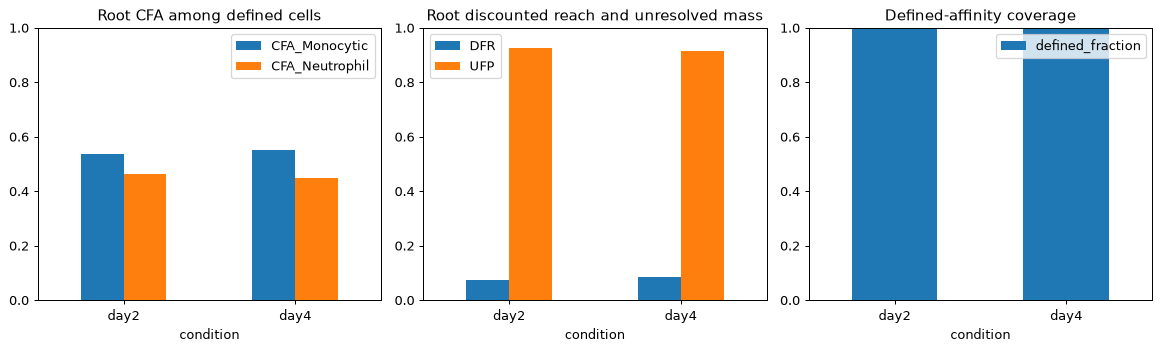

In [9]:
pooled = pair.result
rows = []
for condition, result in results.items():
    locations = pd.Index(pooled.cell_ids).get_indexer(result.cell_ids)
    assert (locations >= 0).all()
    defined = pooled.affinity_defined[locations]
    row = {
        "condition": condition,
        "n_root_cells": len(locations),
        "n_defined_CFA": int(defined.sum()),
        "defined_fraction": float(defined.mean()),
        "DFR": float(pooled.discounted_fate_reach[locations].mean()),
        "UFP": float(pooled.unresolved_probability[locations].mean()),
        "SOF": float(pooled.signed_progression[locations].mean()),
    }
    for j, fate in enumerate(pooled.fate_names):
        row["CFA_" + fate] = (
            float(pooled.conditional_fate_affinity[locations[defined], j].mean())
            if defined.any()
            else np.nan
        )
    rows.append(row)
summary = pd.DataFrame(rows)
display(summary)
summary.to_csv(OUTPUT_DIR / "condition_summary.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
summary.set_index("condition")[["CFA_" + f for f in FATES]].plot.bar(ax=axes[0], ylim=(0, 1))
summary.set_index("condition")[["DFR", "UFP"]].plot.bar(ax=axes[1], ylim=(0, 1))
summary.set_index("condition")[["defined_fraction"]].plot.bar(ax=axes[2], ylim=(0, 1))
axes[0].set_title("Root CFA among defined cells")
axes[1].set_title("Root discounted reach and unresolved mass")
axes[2].set_title("Defined-affinity coverage")
for axis in axes:
    axis.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()

**What the pooled score measures.** 599/600 day-2 roots and 600/600 day-4 roots clear the reach threshold. Mean monocytic CFA among those roots is 0.538 and 0.550. Mean reach across all roots is 0.073 and 0.086. Even with near-complete coverage, those conditional proportions can coexist with little discounted mass arriving at either late endpoint.

## 8. Compare conditions on the same star

These are shared-geometry displays of the native-graph results. Refitting dynamics in the star would change the model and is not performed. Inspect population identity, each fate's CFA, selected-fate reach, unresolved probability and Signed Ordering Flux (SOF). SOF describes movement relative to the chosen ordering; it is not an independent measurement of chronological maturation.

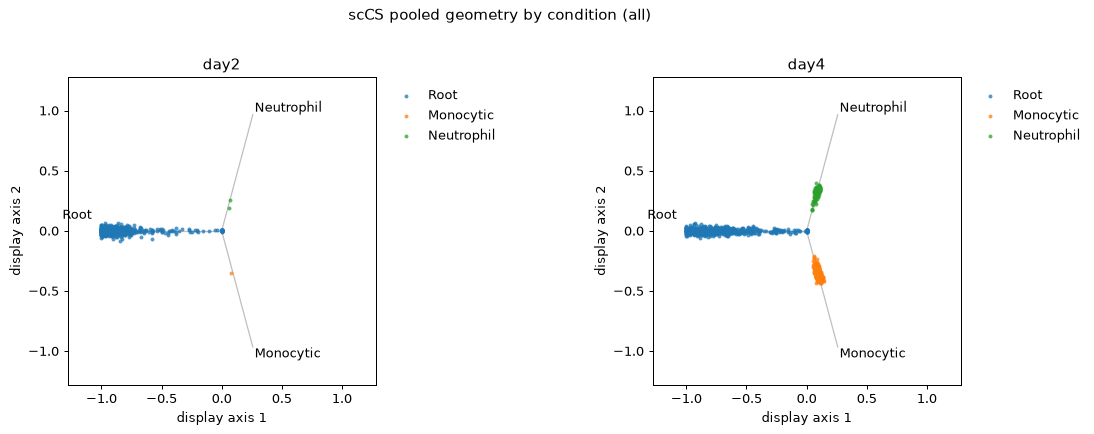

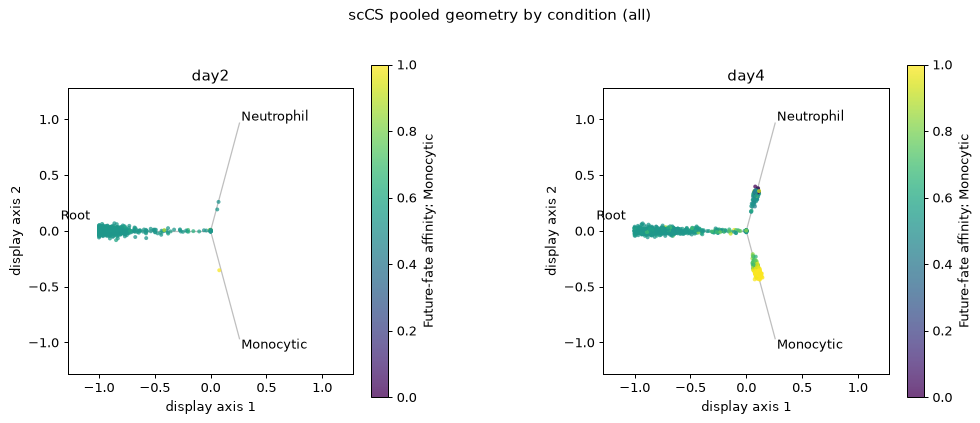

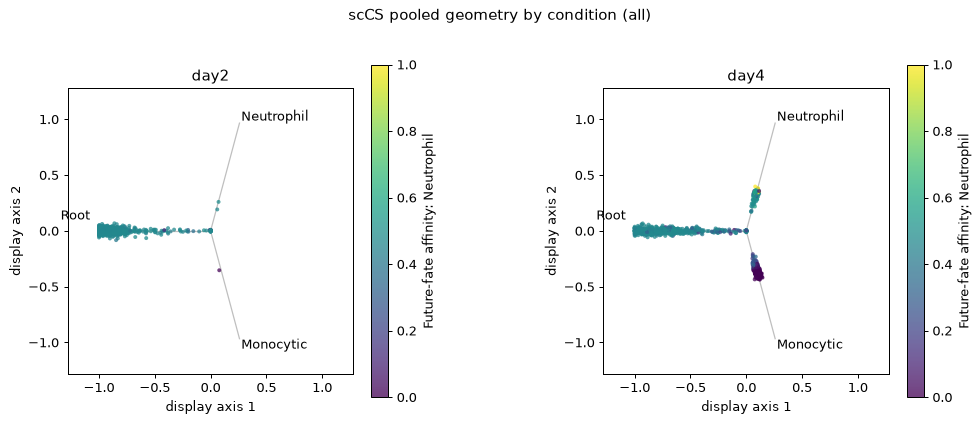

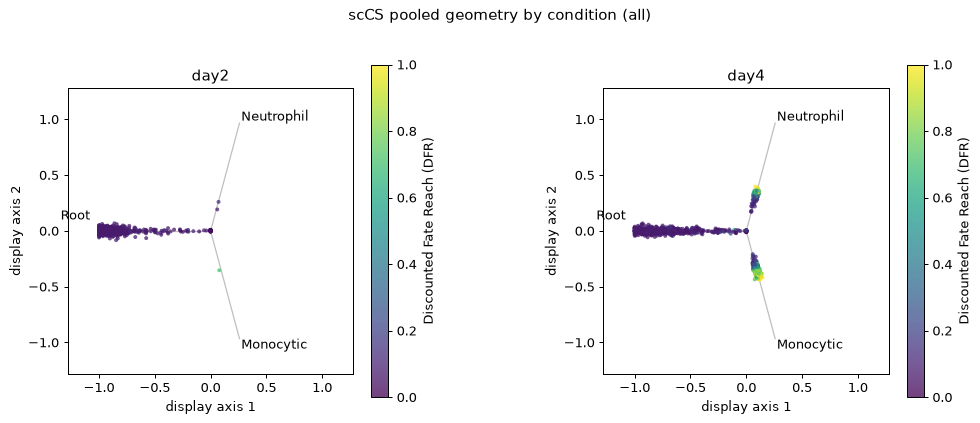

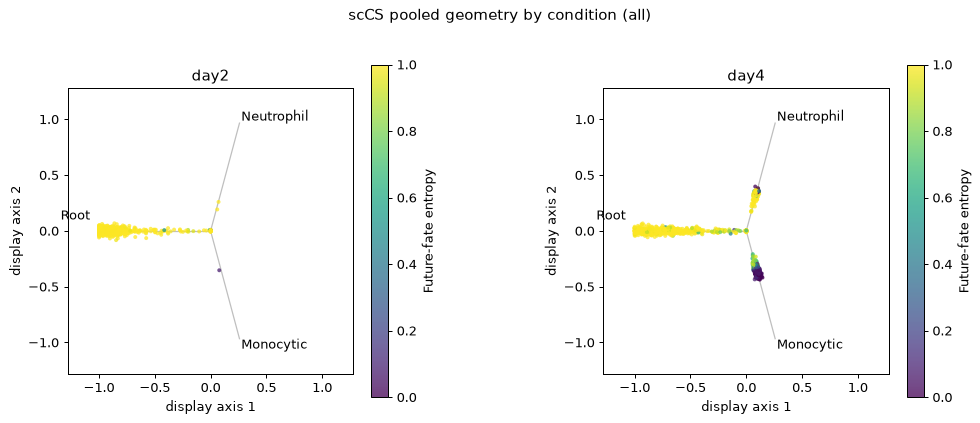

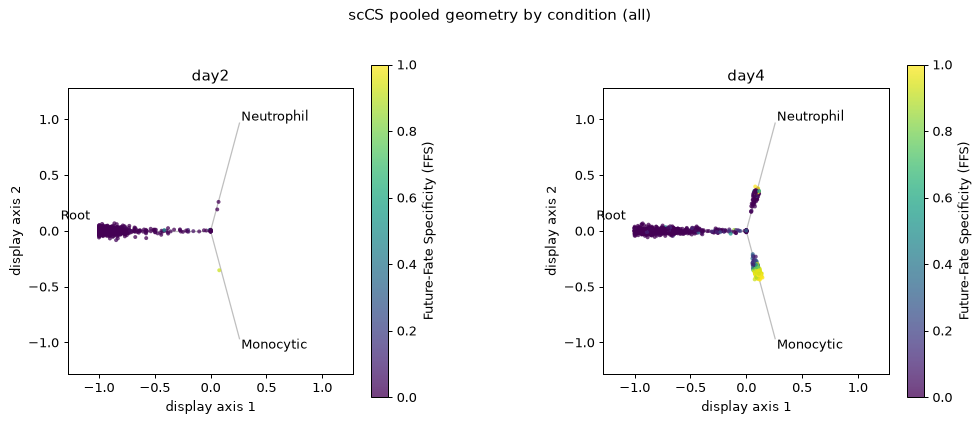

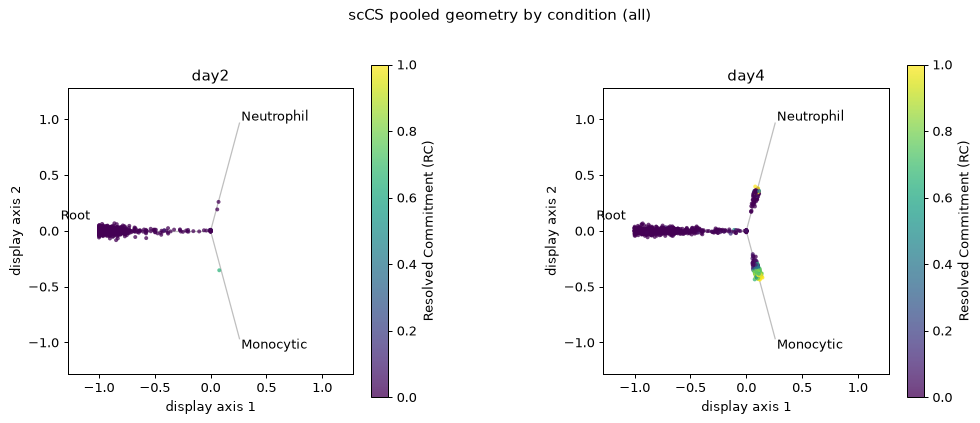

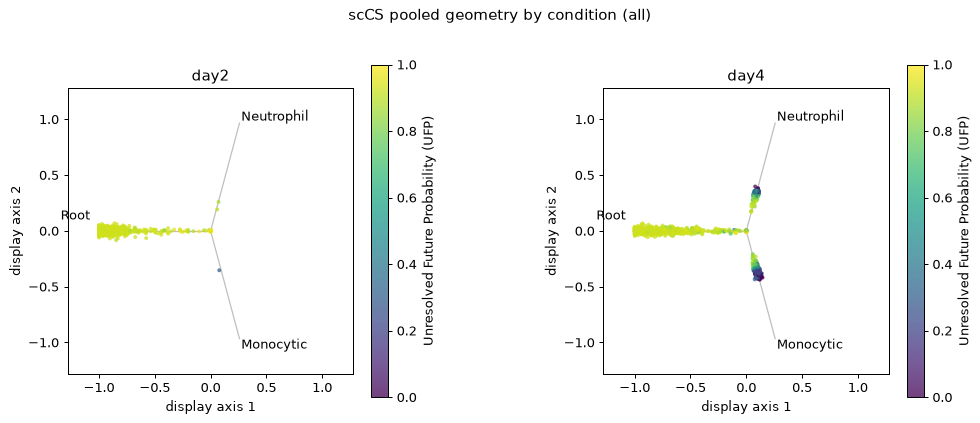

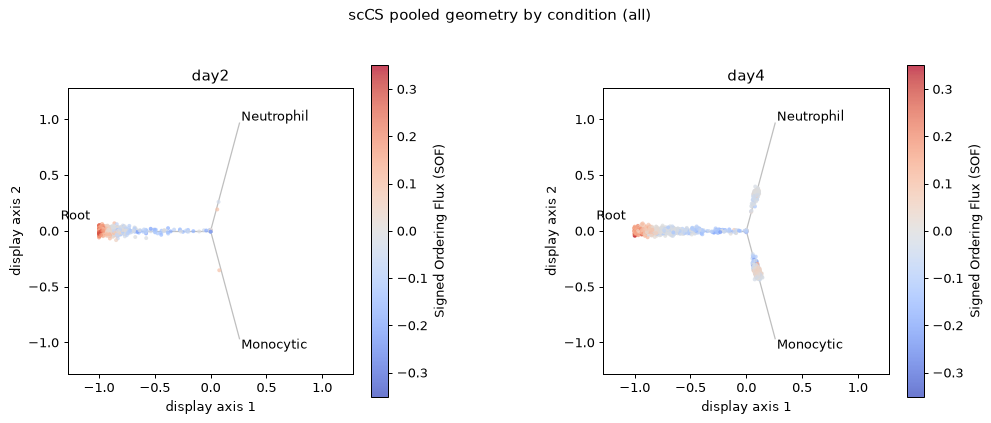

In [10]:
star_metrics = [
    "population",
    *["future_fate_affinity:" + f for f in FATES],
    "future_fate_reach",
    "future_fate_entropy",
    "future_fate_specificity",
    "reach_supported_specificity",
    "unresolved_future_probability",
    "signed_progression",
]
for color_by in star_metrics:
    figure = pair.plot_star_grid(
        results, color_by=color_by, population="all", ncols=2, figsize_per_panel=(6.4, 4.8)
    )
    if color_by == "population":
        figure.subplots_adjust(wspace=0.9)
    plt.show()

## 9. Inspect status, transition coverage and expression

Status and mean root graph-coverage plots help distinguish missing information from a conditional preference. The coverage bars have no replicate confidence intervals. Marker expression is shown from the normalized, log-transformed `X` matrix on a shared color scale. These panels are descriptive checks rather than differential-expression tests or proof that a root cell produced a particular descendant.

Markers absent after count filtering: ['Lyz2']


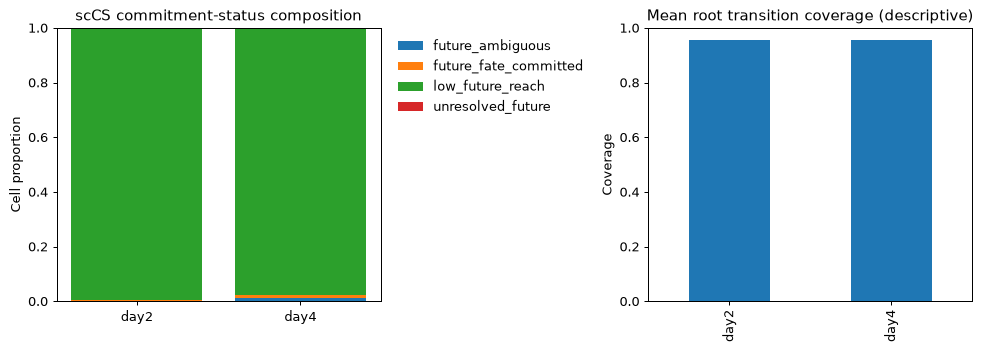

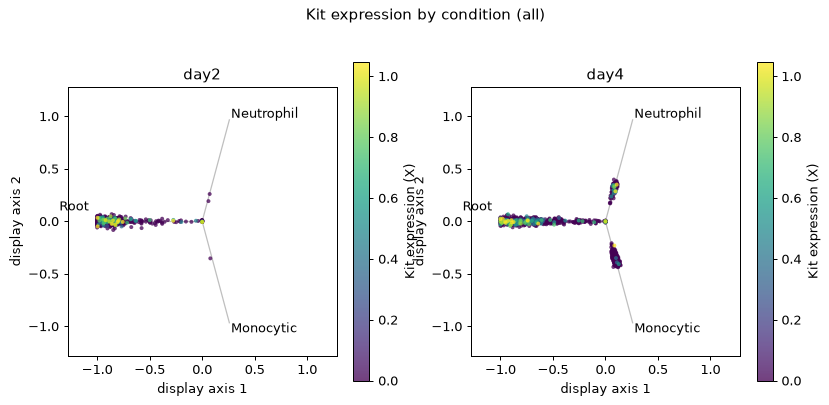

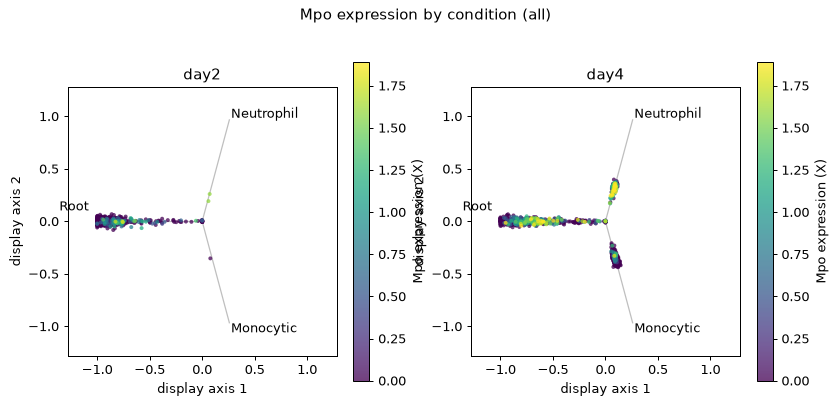

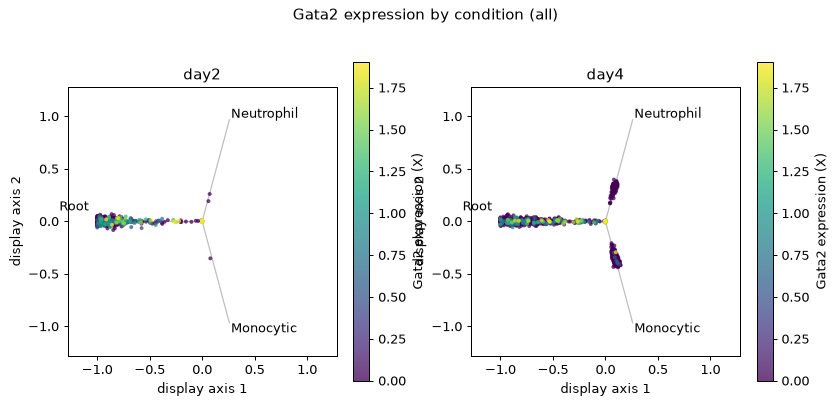

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
pair.plot_status_composition(results, ax=axes[0])
coverage_means = pd.Series(
    {name: np.mean(value.transition_coverage) for name, value in results.items()}
)
coverage_means.plot.bar(ax=axes[1], ylim=(0, 1))
axes[1].set_title("Mean root transition coverage (descriptive)")
axes[1].set_ylabel("Coverage")
fig.tight_layout()
plt.show()
print(
    "Markers absent after count filtering:", [g for g in MARKER_GENES if g not in adata.var_names]
)
for gene in MARKER_GENES:
    if gene in adata.var_names:
        pair.plot_gene_expression_star_grid(
            gene, results, shared_scale=True, ncols=2, figsize_per_panel=(5.3, 4.6)
        )
        plt.show()

## 10. Sensitivity to borrowing between conditions

The pooled graph can borrow neighbors across conditions. Blocking cross-condition transitions tests a different graph assumption while retaining the same velocity fit and supervised outcome definition. It does not refit scVelo independently in each condition. Lower reach after blocking can result from lost graph connections; it is not automatically evidence for biological arrest.

In [12]:
scope_rows = []
for scope in ["pooled", "condition"]:
    sensitivity = scCS.PairScorer(
        adata,
        root=ROOT_LABEL,
        branches=FATES,
        obs_key="clusters",
        condition_obs_key="condition",
        replicate_obs_key=REPLICATE_KEY,
        condition_order=list(results),
    )
    sensitivity.build_embedding(ordering_metric=ORDERING_KEY, cache_subset=False, verbose=False)
    sensitivity.fit(
        transition_matrix=transition,
        scoring_mode="future_fate",
        transition_scope=scope,
        future_fate_options=FUTURE_OPTIONS,
        verbose=False,
    )
    condition_results = sensitivity.score_all_conditions(
        population="root", min_cells=5, min_replicates=1, write_to_adata=False, verbose=False
    )
    for condition, result in condition_results.items():
        scope_rows.append(
            {
                "scope": scope,
                "condition": condition,
                "DFR": float(np.mean(result.commitment_strength)),
                "UFP": float(np.mean(result.unresolved_probability)),
                "defined_fraction": float(np.mean(result.affinity_defined)),
            }
        )
scope_summary = pd.DataFrame(scope_rows)
display(scope_summary)
scope_summary.to_csv(OUTPUT_DIR / "transition_scope_sensitivity.csv", index=False)

,scope,condition,DFR,UFP,defined_fraction
0,pooled,day2,0.072977,0.927023,0.998333
1,pooled,day4,0.086116,0.913884,1.000000
2,condition,day2,0.000000,1.000000,0.000000
3,condition,day4,0.106544,0.893456,1.000000


**Why day-2 reach becomes zero.** All 39 late monocytic anchors and all 13 late neutrophil anchors belong to day 4. Once cross-day edges are removed, day-2 roots cannot reach any late anchor by construction. Their CFA is undefined. The pooled estimate describes access to a later reference population, and the blocked result follows from the reference design. It supplies no evidence that day-2 progenitors lack differentiation potential.

## Complete scalar and fate-wise outcome tables

Each row below is a root cell, and each summary explicitly counts finite values. Conditional affinity, entropy and specificity remain undefined when the selected fates cannot be reached. Means across cells describe this observed sample; they are not biological-replicate estimates or confidence intervals. The exported cell table makes the denominators inspectable.

In [13]:
cell_tables = []
for condition, result in results.items():
    table = pd.DataFrame(
        {
            "condition": condition,
            "cell_id": result.cell_ids,
            "ordering": adata.obs.loc[result.cell_ids, ORDERING_KEY].to_numpy(),
            "DFR": result.commitment_strength,
            "UFP": result.unresolved_probability,
            "conditional_entropy": result.directional_entropy,
            "conditional_specificity": result.directional_specificity,
            "reach_supported_specificity": result.specific_commitment,
            "SOF": result.progression_velocity,
            "path_coverage": result.transition_coverage,
        }
    )
    for j, fate in enumerate(FATES):
        table["CFA_" + fate] = result.directional_affinity[:, j]
        table["contribution_" + fate] = result.commitment_contribution[:, j]
    cell_tables.append(table)
cell_table = pd.concat(cell_tables, ignore_index=True)
metric_columns = [c for c in cell_table if c not in ["condition", "cell_id", "ordering"]]
outcomes = cell_table.groupby("condition", observed=True)[metric_columns].agg(["mean", "count"])
with pd.option_context("display.max_columns", None, "display.width", 180):
    display(outcomes.T)
cell_table.to_csv(OUTPUT_DIR / "root_cell_outcomes.csv", index=False)
outcomes.to_csv(OUTPUT_DIR / "complete_outcome_summary.csv")

condition                                day2        day4
DFR                         mean     0.072977    0.086116
                            count  600.000000  600.000000
UFP                         mean     0.927023    0.913884
                            count  600.000000  600.000000
conditional_entropy         mean     0.991451    0.980058
                            count  599.000000  600.000000
conditional_specificity     mean     0.008549    0.019942
                            count  599.000000  600.000000
reach_supported_specificity mean     0.001411    0.005621
                            count  600.000000  600.000000
SOF                         mean     0.046932    0.017079
                            count  600.000000  600.000000
path_coverage               mean     0.955077    0.957549
                            count  600.000000  600.000000
CFA_Monocytic               mean     0.538140    0.550438
                            count  599.000000  600.000000
contribution_Monocytic      mean     0.039836    0.050314
                            count  600.000000  600.000000
CFA_Neutrophil              mean     0.461860    0.449562
                            count  599.000000  600.000000
contribution_Neutrophil     mean     0.033141    0.035803
                            count  600.000000  600.000000

## How much did the scores change?

The contrast is **day4 minus day2**. DFR measures discounted access to either destination. Each endpoint contribution averages over all roots, including roots with zero reach. CFA averages over defined roots. Read its denominator alongside the change. Each cell has equal weight within its group. The values describe the sampled roots.

,roots,defined roots
condition,,
day2,600,599
day4,600,600


condition,day2,day4,change
DFR,0.0730,0.0861,0.0131
UFP,0.9270,0.9139,-0.0131
defined fraction,0.9983,1.0000,0.0017
contribution_Monocytic,0.0398,0.0503,0.0105
contribution_Neutrophil,0.0331,0.0358,0.0027
CFA_Monocytic,0.5381,0.5504,0.0123
CFA_Neutrophil,0.4619,0.4496,-0.0123


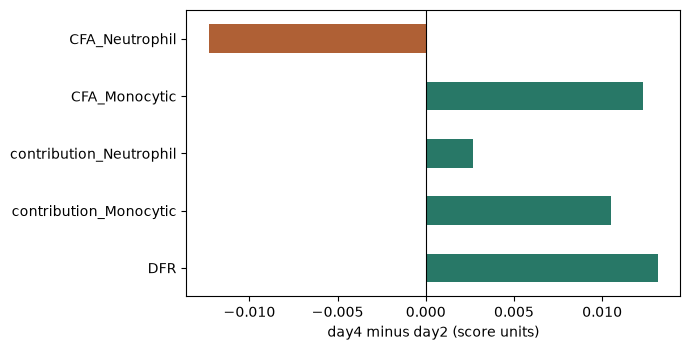

In [20]:
comp = cell_table.copy()
arms = ['day2', 'day4']
affinities = ['CFA_Monocytic', 'CFA_Neutrophil']
contributions = ['contribution_Monocytic', 'contribution_Neutrophil']
comp["defined fraction"] = comp[affinities].notna().all(axis=1)
metrics = ["DFR", "UFP", "defined fraction"] + contributions + affinities
arm = comp.groupby("condition", observed=True)[metrics].mean().reindex(arms)
effect = arm.T.copy()
effect["change"] = effect[arms[1]] - effect[arms[0]]
counts = (
    comp.groupby("condition", observed=True)["defined fraction"].agg(["size", "sum"]).reindex(arms)
)
display(counts.rename(columns={"size":"roots","sum":"defined roots"}))
display(effect.round(4))
np.testing.assert_allclose(effect.loc[contributions,"change"].sum(),effect.loc["DFR","change"],atol=1e-9)
effect.to_csv(OUTPUT_DIR / "condition_contrast.csv")
panel = effect.loc[["DFR"] + contributions + affinities,"change"]
ax = panel.plot.barh(figsize=(7,3.6),color=np.where(panel>=0,"#287867","#af6035"))
ax.axvline(0,color="black",lw=.8)
ax.set_xlabel(arms[1] + " minus " + arms[0] + " (score units)")
plt.tight_layout()
plt.show()

Mean DFR changed by **+0.0131**. The day-4 roots show a small increase in reach and in conditional monocytic affinity on the pooled graph. The within-day graph check shows how much this estimate depends on access to the later culture.

## Condition summaries, composition and trajectory shifts

The contribution bar chart and heatmaps display sample means, with no cell-resampling error bars. The radar normalizes the mean fate contributions and therefore summarizes reach-weighted composition; it need not equal mean CFA. The SOF histogram describes cell-level movement relative to the specified ordering, not a test of developmental progression between independent experiments.

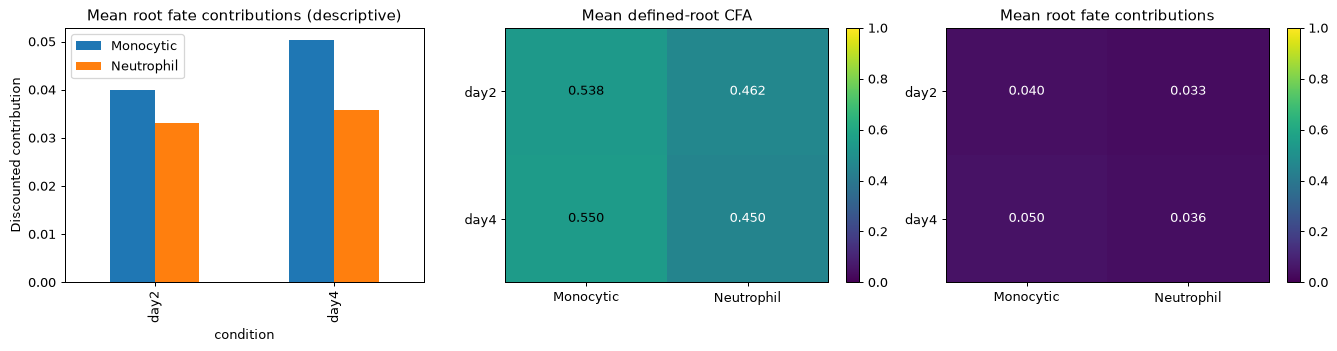

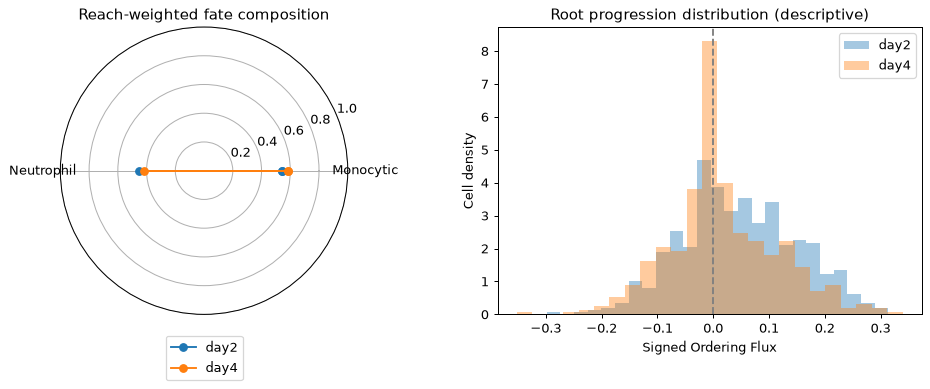

In [14]:
means = cell_table.groupby("condition", observed=True)[metric_columns].mean().reindex(results)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
means[["contribution_" + f for f in FATES]].rename(
    columns={"contribution_" + f: f for f in FATES}
).plot.bar(ax=axes[0])
axes[0].set_title("Mean root fate contributions (descriptive)")
axes[0].set_ylabel("Discounted contribution")
for axis, columns, title in [
    (axes[1], ["CFA_" + f for f in FATES], "Mean defined-root CFA"),
    (axes[2], ["contribution_" + f for f in FATES], "Mean root fate contributions"),
]:
    values = means[columns].to_numpy()
    image = axis.imshow(values, vmin=0, vmax=1, cmap="viridis", aspect="auto")
    axis.set(
        xticks=np.arange(len(FATES)),
        xticklabels=FATES,
        yticks=np.arange(len(means)),
        yticklabels=means.index,
        title=title,
    )
    for row in range(len(means)):
        for column in range(len(FATES)):
            value = values[row, column]
            axis.text(
                column,
                row,
                f"{value:.3f}" if np.isfinite(value) else "undefined",
                ha="center",
                va="center",
                color="white" if value < 0.5 else "black",
            )
    fig.colorbar(image, ax=axis, fraction=0.05)
fig.tight_layout()
plt.show()

fig = plt.figure(figsize=(11, 4.5))
radar = fig.add_subplot(121, projection="polar")
hist = fig.add_subplot(122)
angles = np.linspace(0, 2 * np.pi, len(FATES), endpoint=False)
for condition in results:
    values = means.loc[condition, ["contribution_" + f for f in FATES]].to_numpy(float)
    if values.sum() > 0:
        values /= values.sum()
        radar.plot(np.r_[angles, angles[0]], np.r_[values, values[0]], marker="o", label=condition)
    values = cell_table.loc[cell_table.condition.eq(condition), "SOF"]
    hist.hist(values[np.isfinite(values)], bins=25, density=True, alpha=0.4, label=condition)
radar.set_xticks(angles, FATES)
radar.set_ylim(0, 1)
radar.set_title("Reach-weighted fate composition")
radar.legend(loc="lower center", bbox_to_anchor=(0.5, -0.25))
hist.axvline(0, color="0.5", linestyle="--")
hist.set(
    xlabel="Signed Ordering Flux",
    ylabel="Cell density",
    title="Root progression distribution (descriptive)",
)
hist.legend()
fig.tight_layout()
plt.show()

## Ordering trends with observed-cell denominators

Common ordering bins are used across both conditions. The curves below summarize observed root cells, and the accompanying table records the number of finite values in each bin. They have no biological-replicate confidence bands. This explicit descriptive calculation is used instead of calling the replicate-aware trend API with invented replicate IDs.

ordering       CFA_Monocytic             DFR  \
                                mean count          mean count      mean   
condition ordering_bin                                                     
day2      (-0.001, 0.0142]  0.009806    96      0.533295    96  0.072829   
          (0.0142, 0.0211]  0.017616   100      0.533643   100  0.073131   
          (0.0211, 0.0271]  0.024150    94      0.535210    94  0.073427   
          (0.0271, 0.0347]  0.030887    91      0.539148    91  0.075192   
          (0.0347, 0.0433]  0.038661    93      0.536573    93  0.074238   
          (0.0433, 0.062]   0.050333    51      0.533140    51  0.074754   
          (0.062, 0.101]    0.078433    29      0.534434    29  0.077582   
          (0.101, 0.851]    0.214129    46      0.573850    45  0.060223   
day4      (-0.001, 0.0142]  0.010149    54      0.536817    54  0.073943   
          (0.0142, 0.0211]  0.017948    50      0.535303    50  0.074065   
          (0.0211, 0.0271]  0.024087    56      0.537705    56  0.074918   
          (0.0271, 0.0347]  0.031052    59      0.539651    59  0.076409   
          (0.0347, 0.0433]  0.038401    57      0.537627    57  0.076519   
          (0.0433, 0.062]   0.051906    99      0.541977    99  0.080763   
          (0.062, 0.101]    0.077817   121      0.541245   121  0.081292   
          (0.101, 0.851]    0.185070   104      0.603536   104  0.125738   

                                       SOF        
                           count      mean count  
condition ordering_bin                            
day2      (-0.001, 0.0142]    96  0.184096    96  
          (0.0142, 0.0211]   100  0.129176   100  
          (0.0211, 0.0271]    94  0.069184    94  
          (0.0271, 0.0347]    91  0.012154    91  
          (0.0347, 0.0433]    93 -0.017477    93  
          (0.0433, 0.062]     51 -0.048866    51  
          (0.062, 0.101]      29 -0.089065    29  
          (0.101, 0.851]      46 -0.072616    46  
day4      (-0.001, 0.0142]    54  0.177219    54  
          (0.0142, 0.0211]    50  0.130900    50  
          (0.0211, 0.0271]    56  0.099999    56  
          (0.0271, 0.0347]    59  0.048938    59  
          (0.0347, 0.0433]    57  0.011073    57  
          (0.0433, 0.062]     99 -0.013959    99  
          (0.062, 0.101]     121 -0.047715   121  
          (0.101, 0.851]     104 -0.075295   104

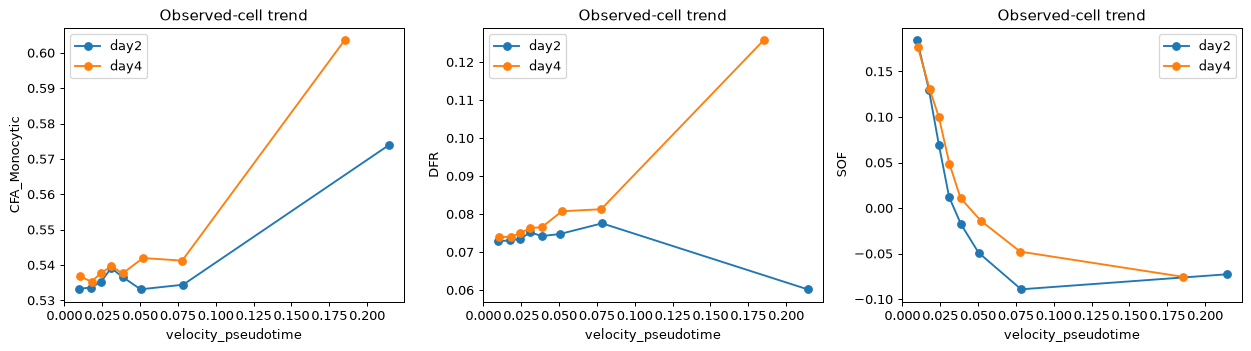

In [15]:
edges = np.unique(np.quantile(cell_table.ordering, np.linspace(0, 1, 9)))
if len(edges) < 4:
    raise ValueError("The root ordering has too few distinct values for trend plots.")
cell_table["ordering_bin"] = pd.cut(cell_table.ordering, bins=edges, include_lowest=True)
trend_columns = ["ordering", "CFA_" + FATES[0], "DFR", "SOF"]
trends = cell_table.groupby(["condition", "ordering_bin"], observed=True)[trend_columns].agg(
    ["mean", "count"]
)
with pd.option_context("display.max_rows", 40, "display.max_columns", None):
    display(trends)
trends.to_csv(OUTPUT_DIR / "descriptive_ordering_trends.csv")
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for condition in results:
    curve = trends.loc[condition]
    for axis, metric in zip(axes, ["CFA_" + FATES[0], "DFR", "SOF"]):
        axis.plot(curve[("ordering", "mean")], curve[(metric, "mean")], marker="o", label=condition)
        axis.set(xlabel=ORDERING_KEY, ylabel=metric, title="Observed-cell trend")
for axis in axes:
    axis.legend()
fig.tight_layout()
plt.show()

## Instantaneous velocity roses, fitted independently from DFFP

As in the other PairScorer tutorials, the root roses summarize instantaneous fate-directed velocity after accounting for incoming-root progression. They are a display diagnostic rather than discounted future-fate probabilities. A separate pooled instantaneous scorer protects the primary DFFP result from being overwritten.

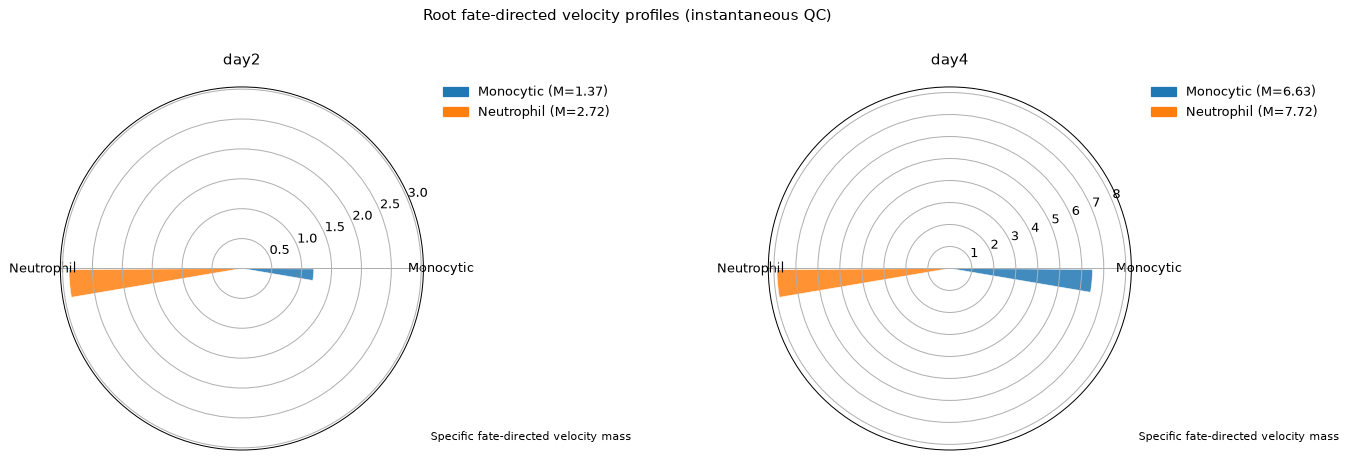

In [16]:
display_pair = scCS.PairScorer(
    adata,
    root=ROOT_LABEL,
    branches=FATES,
    obs_key="clusters",
    condition_obs_key="condition",
    replicate_obs_key=REPLICATE_KEY,
    condition_order=list(results),
)
display_pair.build_embedding(ordering_metric=ORDERING_KEY, cache_subset=False, verbose=False)
display_pair.fit(
    transition_matrix=transition,
    scoring_mode="instantaneous",
    transition_scope="pooled",
    verbose=False,
)
display_results = display_pair.score_all_conditions(
    population="root", min_cells=1, min_replicates=1, write_to_adata=False, verbose=False
)
rose_figure = display_pair.plot_rose_grid(
    display_results,
    population="root",
    mode="branch",
    n_bins=36,
    ncols=2,
    title="Root fate-directed velocity profiles (instantaneous QC)",
)
rose_figure.set_size_inches(14, 5.5)
rose_figure.subplots_adjust(wspace=0.95, left=0.05, right=0.9)
plt.show()

## 11. Respect the experimental unit

The source metadata are retained without inventing donors from cells, library batches, time points or clone barcodes. A formal PairScorer comparison is attempted below to show that the unsupported design is rejected. The appropriate output here is descriptive scores with explicit coverage. Independent biological replication, and an analysis that respects any pairing, would be required for inference about a population-level change across culture time.

In [17]:
# Requesting a formal test must fail rather than use cells as independent replicates.
try:
    pair.compare_conditions(results, metric="future_fate_reach", verbose=False)
except ValueError as error:
    print("Formal inference is unavailable for this design:", error)
    inference_refused = True
else:
    raise AssertionError("This descriptive design must not produce a treatment p-value.")
inference_audit = pd.DataFrame(
    [
        {
            "analysis": name,
            "status": "not estimable for this experimental design",
            "reason": "one patient per condition"
            if REPLICATE_KEY
            else "no independent-replicate metadata",
        }
        for name in [
            "replicate permutation test",
            "biological-replicate bootstrap",
            "replicate mixed model",
        ]
    ]
)
display(inference_audit)
inference_audit.to_csv(OUTPUT_DIR / "inference_availability.csv", index=False)

Formal inference is unavailable for this design: compare_conditions requires replicate_obs_key. Cell-level permutation is intentionally not used for formal inference.


,analysis,status,reason
0,replicate permutation test,not estimable for this experimental design,no independent-replicate metadata
1,biological-replicate bootstrap,not estimable for this experimental design,no independent-replicate metadata
2,replicate mixed model,not estimable for this experimental design,no independent-replicate metadata


## 12. Export and interpretation

The analysis object stores the actual splicing layers after normalization, fitted velocity vectors, native neighbor graph, UMAP, ordering and scCS scores. The source count files and checksums remain the reference for raw molecules. CSV exports record the condition summaries, graph-scope sensitivity and velocity diagnostics. Figures are retained in this executed notebook for Read the Docs.

Dynamical velocity is undefined for some unfitted genes. The final checks validate the selected velocity genes and the transition graph; undefined values outside that set are retained rather than replaced with artificial velocities.

In [18]:
pair.result.write_to_adata(adata)
adata.write_h5ad(OUTPUT_DIR / "pair_scorer_velocity_analysis.h5ad", compression="gzip")
adata.obs[
    ["condition", "source_state", "velocity_length", "velocity_confidence", ORDERING_KEY]
].to_csv(OUTPUT_DIR / "velocity_and_ordering_qc.csv")
assert inference_refused
assert summary.n_root_cells.gt(0).all()
assert summary.defined_fraction.between(0, 1).all()
modeled_genes = adata.var.velocity_genes.to_numpy(bool)
assert modeled_genes.any()
assert np.isfinite(adata.layers["velocity"][:, modeled_genes]).all()
assert np.isfinite(transition.data).all()
print("Validated velocity genes:", int(modeled_genes.sum()), "of", adata.n_vars)
print("Undefined velocities outside the fitted gene set are retained.")
print(
    "Saved fitted velocity, scCS scores, figures in notebook outputs, and QC tables to", OUTPUT_DIR
)
fit_columns = [c for c in adata.var if c.startswith("fit_") or c == "velocity_genes"]
adata.var[fit_columns].to_csv(OUTPUT_DIR / "dynamical_gene_fits.csv")
adata.obs[["condition", "source_state", "latent_time", "velocity_pseudotime"]].to_csv(
    OUTPUT_DIR / "dynamical_time_qc.csv"
)

provenance = {
    "python": platform.python_version(),
    "velocity_mode": "dynamical",
    "recover_dynamics_max_iter": 20,
    "random_seed": SEED,
    "versions": {
        name: metadata.version(name)
        for name in ["scCS-py", "scanpy", "scvelo", "anndata", "numpy", "scipy", "pandas"]
    },
}
(OUTPUT_DIR / "execution_environment.json").write_text(json.dumps(provenance, indent=2))

Validated velocity genes: 609 of 1704
Undefined velocities outside the fitted gene set are retained.
Saved fitted velocity, scCS scores, figures in notebook outputs, and QC tables to /workspace/scratch/1a48413c8396/replay/tutorial_outputs/larry_pair_velocity


## Check the scores and change the endpoint definition

The first calculation checks the primary scores with an independent numerical method. The second changes where a walk stops, from the late anchors to the first cell bearing either fate annotation. The velocity field, cells, discount and root labels stay fixed. Endpoints are counted within each day even when the graph is pooled. A root has defined conditional fate affinity (CFA) when its discounted reach to either endpoint is at least 10⁻⁶.

In [19]:
# Recalculate discounted first-hit probabilities without calling the scCS solver.
# Each iteration adds one possible transition. Endpoint cells keep their one-hot boundary values.
from scipy import sparse

model = adata.uns["sccs_v08"]["future_fate"]
fates = list(model["fate_names"])
days = adata.obs["condition"].astype(str).to_numpy()
labels = adata.obs["clusters"].astype(str).to_numpy()
order = adata.obs[ORDERING_KEY].to_numpy()
late = np.zeros((adata.n_obs, len(fates)), dtype=bool)
for j, fate in enumerate(fates):
    candidates = np.flatnonzero(labels == fate)
    values = order[candidates]
    chosen = candidates[values >= np.quantile(values, model["anchor_quantile"])]
    minimum = min(int(model["min_anchor_cells"]), len(candidates))
    if len(chosen) < minimum:
        chosen = candidates[np.argsort(values, kind="stable")[-minimum:]]
    assert set(adata.obs_names[chosen]) == set(model["anchor_cell_ids"][fate])
    late[chosen, j] = True

def discounted_hits(matrix, endpoints, discount):
    values = endpoints.astype(float)
    transient = ~endpoints.any(axis=1)
    for _ in range(4000):
        updated = discount * (matrix @ values)
        updated[~transient] = endpoints[~transient]
        if np.max(np.abs(updated - values)) < 1e-14:
            return updated
        values = updated
    raise RuntimeError("Independent discounted-walk calculation did not converge.")

graph = adata.obsp["T_velocity"].astype(float).tocoo()
assert np.isfinite(graph.data).all() and (graph.data >= 0).all()
np.testing.assert_allclose(np.asarray(graph.sum(axis=1)).ravel(), 1, atol=1e-6, rtol=0)
all_labelled = np.column_stack([labels == fate for fate in fates])
diagnostics = []
for scope in ["pooled", "condition"]:
    keep = (
        np.ones(graph.nnz, dtype=bool) if scope == "pooled" else days[graph.row] == days[graph.col]
    )
    matrix = sparse.csr_matrix(
        (graph.data[keep], (graph.row[keep], graph.col[keep])), shape=graph.shape
    )
    totals = np.asarray(matrix.sum(axis=1)).ravel()
    empty = totals <= 1e-12
    matrix = sparse.diags(1 / np.where(empty, 1, totals)) @ matrix + sparse.diags(
        empty.astype(float)
    )
    for definition, endpoints in [
        ("late anchors", late),
        ("any annotated fate cell", all_labelled),
    ]:
        hits = discounted_hits(matrix, endpoints, float(model["gamma"]))
        reach = hits.sum(axis=1)
        defined = reach >= model["min_reach"]
        cfa = np.full_like(hits, np.nan)
        cfa[defined] = hits[defined] / reach[defined, None]
        for day in sorted(set(days)):
            roots = (labels == ROOT_LABEL) & (days == day)
            covered = roots & defined
            if definition == "late anchors":
                target = scope_summary.set_index(["scope", "condition"]).loc[(scope, day)]
                np.testing.assert_allclose(
                    [reach[roots].mean(), 1 - reach[roots].mean(), defined[roots].mean()],
                    target[["DFR", "UFP", "defined_fraction"]].to_numpy(float), atol=1e-9, rtol=0
                )
                if scope == "pooled":
                    csv_rows = cell_table.set_index("cell_id").loc[adata.obs_names[roots]]
                    np.testing.assert_allclose(
                        hits[roots],
                        csv_rows[["contribution_" + f for f in fates]],
                        atol=1e-9,
                        rtol=0,
                    )
                    np.testing.assert_allclose(
                        cfa[roots],
                        csv_rows[["CFA_" + f for f in fates]],
                        atol=1e-8,
                        rtol=0,
                        equal_nan=True,
                    )
            diagnostics.append(
                {
                    "graph": scope,
                    "endpoint definition": definition,
                    "day": day,
                    **{
                        f + " endpoints": int(endpoints[days == day, j].sum())
                        for j, f in enumerate(fates)
                    },
                    "roots": int(roots.sum()),
                    "defined roots": int(covered.sum()),
                    "mean DFR": reach[roots].mean(),
                    "mean monocytic CFA among defined": cfa[covered, 0].mean()
                    if covered.any()
                    else np.nan,
                }
            )
endpoint_check = pd.DataFrame(diagnostics)
display(endpoint_check.round(4))
endpoint_check.to_csv(OUTPUT_DIR / "endpoint_definition_check.csv", index=False)

,graph,endpoint definition,day,Monocytic endpoints,Neutrophil endpoints,roots,defined roots,mean DFR,mean monocytic CFA among defined
0,pooled,late anchors,day2,0,0,600,599,0.0730,0.5381
1,pooled,late anchors,day4,39,13,600,600,0.0861,0.5504
2,pooled,any annotated fate cell,day2,1,2,600,600,0.5096,0.0360
3,pooled,any annotated fate cell,day4,386,120,600,600,0.5258,0.0570
4,condition,late anchors,day2,0,0,600,0,0.0000,NaN
5,condition,late anchors,day4,39,13,600,600,0.1065,0.5644
6,condition,any annotated fate cell,day2,1,2,600,600,0.1133,0.0012
7,condition,any annotated fate cell,day4,386,120,600,600,0.5365,0.0687


## When does a blood progenitor acquire a recognizable myeloid identity?

Among undifferentiated cells in the LARRY culture, the first annotated myeloid state encountered on the pooled graph was usually neutrophilic. Mean monocytic affinity at first entry was 0.036 on day 2 and 0.057 on day 4. When the question was arrival at late monocytic or neutrophilic cells, the same starting populations gave means of 0.538 and 0.550. Early transcriptional identity and access to mature populations therefore give different readings of this culture.

All late anchors came from day 4. Their inclusion allows an early progenitor to be evaluated against both mature populations on a common reference. The original study tracked descendant cells using heritable barcodes. The comparison here uses RNA dynamics; determining whether a particular clone ultimately produced monocytes or neutrophils requires its descendants. [Weinreb et al.](https://doi.org/10.1126/science.aaw3381) · [Velocity dataset](https://doi.org/10.6084/m9.figshare.20780344.v1)